# Diagnostics and robustness
Forecast diagnostics, overlay ablation, deflated Sharpe and parameter sensitivity.

In [1]:
import sys

sys.path.insert(0, "../code")
import pandas as pd
from kairos import config

P = config.PATHS
pd.read_csv(P.tables / "regime_return_link.csv")

,Asset,Window,n,CorrStressNextRet,MeanRetStressed,MeanRetCalm,StressedMonths
0,BTC-USD,initial_window,48,-0.151107,-0.032730,0.105925,11
1,BTC-USD,after,83,0.185886,0.060300,0.006247,32
2,DBC,initial_window,48,-0.143095,0.002748,0.011810,39
3,DBC,after,187,0.172580,0.003883,0.000460,51
4,EFA,initial_window,48,-0.323734,-0.024214,0.015582,24
5,EFA,after,211,0.197683,0.015288,0.003461,69
6,ETH-USD,initial_window,48,0.042775,0.045349,0.040283,28
7,ETH-USD,after,46,0.318039,0.092260,-0.010276,9
8,GLD,initial_window,48,-0.029545,0.016643,0.020769,34
9,GLD,after,201,0.120127,0.005890,0.006439,59


In [2]:
pd.read_csv(P.tables / "ic_diagnostics_summary.csv", index_col=0)

,MeanIC,MeanIC_equities,MeanR2OOS,AssetsPositiveIC,Assets
Variant,,,,,
as_specified,-0.009842,-0.063009,-0.064918,3,9
no_regime_features,-0.019944,-0.092900,-0.065607,4,9
no_stress_features,0.001519,-0.084324,-0.057991,5,9
longer_initial_window,-0.009842,-0.063009,-0.064918,3,9
no_regime_longer_window,-0.019944,-0.092900,-0.065607,4,9


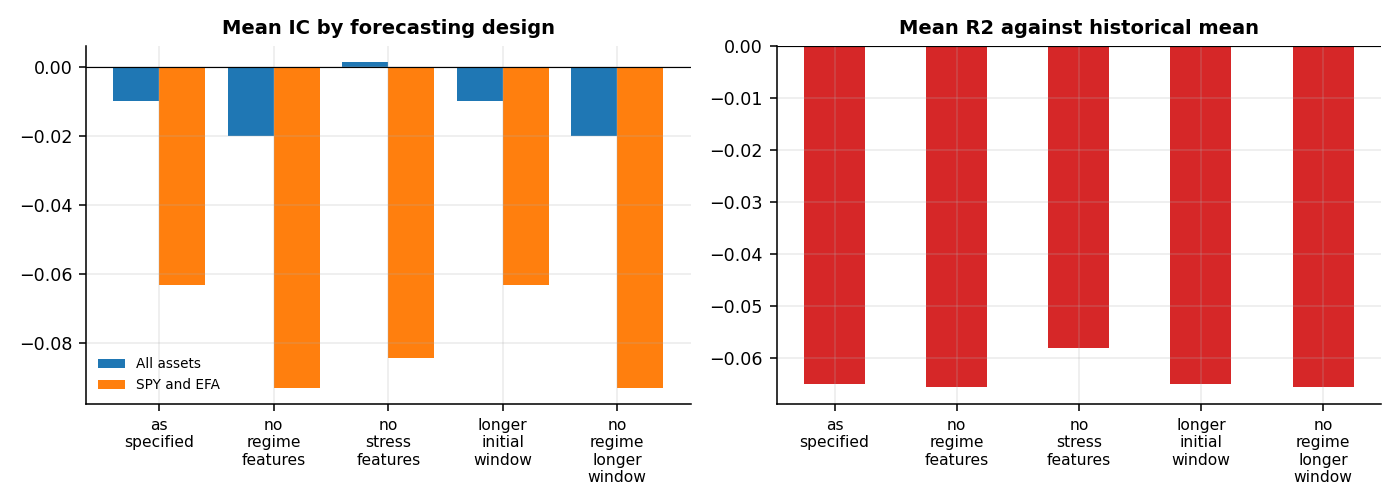

In [3]:
from IPython.display import Image

Image(str(P.figures / "12_ic_diagnostics.png"))

In [4]:
pd.read_csv(P.tables / "deflated_sharpe.csv")

,strategy,Sharpe,BenchmarkSharpe,DSR,Trials
0,BL_ML_Regime,0.804431,0.068916,0.998272,5
1,BL_ML_Regime,0.804431,0.090990,0.997717,10
2,BL_ML_Regime_IC,0.859080,0.068916,0.999071,5
3,BL_ML_Regime_IC,0.859080,0.090990,0.998757,10
4,BL_ML_NoRegime,0.824118,0.068916,0.998640,5
5,BL_ML_NoRegime,0.824118,0.090990,0.998194,10


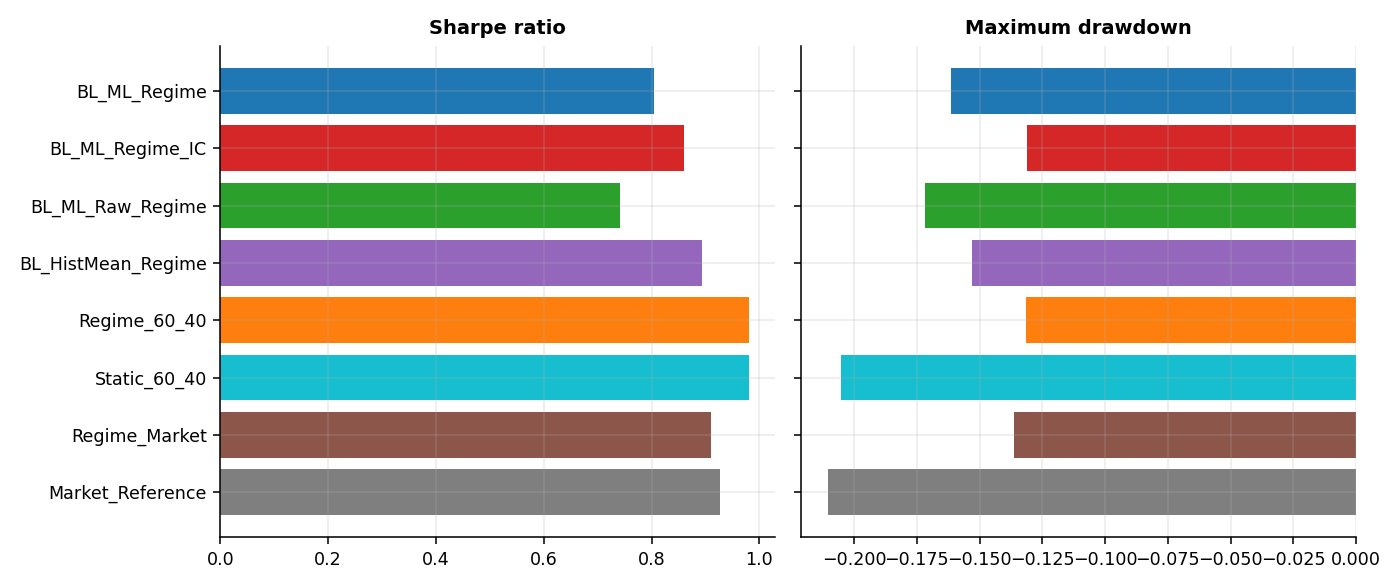

In [5]:
from IPython.display import Image

Image(str(P.figures / "14_overlay_ablation.png"))

In [6]:
pd.read_csv(P.tables / "lstm_repair.csv")

,Asset,n_oos,Disp_raw,R2OOS_raw,IC_raw,Disp_fixed,R2OOS_fixed,IC_fixed
0,BTC-USD,83,0.908460,-1.143499,-0.152974,0.376352,-0.287887,-0.186642
1,DBC,187,1.571743,-2.558854,-0.019832,0.341697,-0.111408,-0.032128
2,EFA,211,2.057775,-3.441643,-0.021512,0.324490,-0.120353,-0.071426
3,ETH-USD,46,1.079048,-1.190229,0.251681,0.513431,-0.306366,0.211964
4,GLD,201,1.505301,-2.778237,-0.105604,0.279617,-0.059370,-0.023613
5,HYG,173,2.530111,-6.710572,-0.041341,0.445434,-0.246705,0.014984
6,IEF,211,2.641537,-6.946565,0.035431,0.272978,-0.116698,0.003390
7,SPY,211,2.087700,-3.750995,0.007026,0.307083,-0.134376,-0.131225
8,TLT,211,2.393833,-5.791665,0.034890,0.241544,-0.051528,0.054284


In [7]:
pd.read_csv(P.tables / "skill_by_period.csv")

,Period,Forecast,MeanIC,MeanR2OOS,AssetsPositiveR2,Assets
0,full,xgb,-0.010116,-0.210809,0,9
1,full,rf,-0.010653,-0.116163,0,9
2,full,ridge,-0.081400,-0.057842,1,9
3,full,lstm,-0.017823,-0.159410,0,9
4,full,pooled_ridge,-0.059822,-0.065613,1,9
5,full,pooled_xgb,-0.051125,-0.093617,1,9
6,full,ensemble_equal,-0.013198,-0.063614,0,9
7,full,ensemble_stacked,-0.062139,-0.095838,0,9
8,full,stack_all,-0.090245,-0.053688,0,9
9,full,ensemble_final,-0.107215,-0.015793,0,9


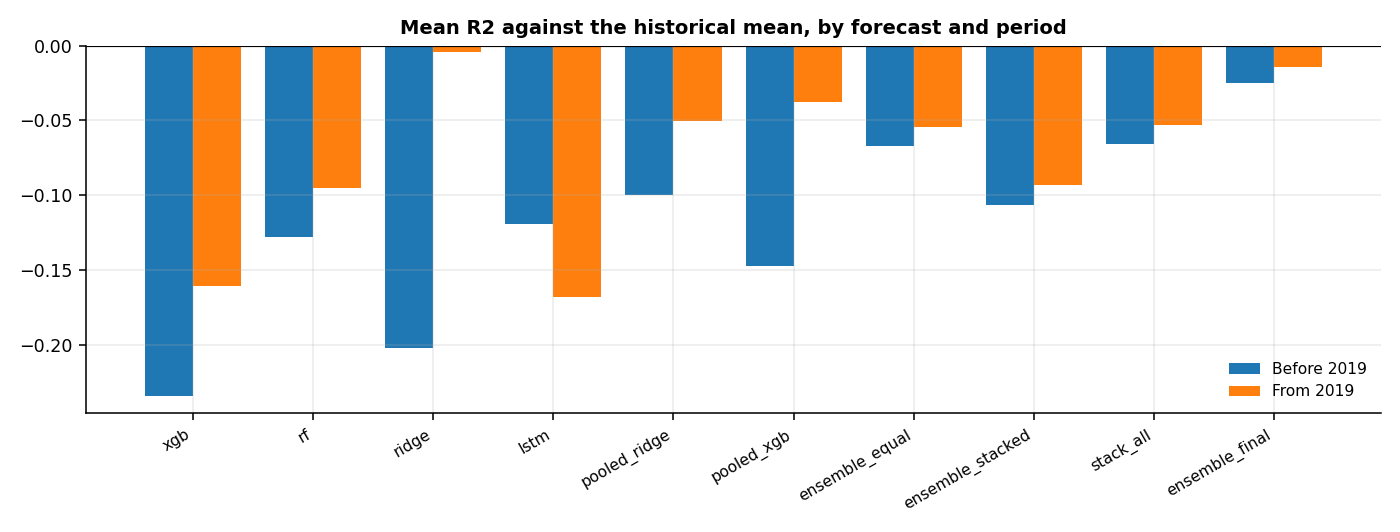

In [8]:
from IPython.display import Image

Image(str(P.figures / "15_forecast_repair.png"))

In [9]:
pd.read_csv(P.tables / "period_split.csv")

,strategy,period,AnnReturn,AnnVol,Sharpe,MaxDrawdown,Months
0,BL_ML_Regime,development,0.059736,0.063738,0.884412,-0.089006,120
1,BL_ML_Regime,holdout,0.091833,0.087719,0.742767,-0.161381,91
2,BL_ML_Regime_IC,development,0.060329,0.060493,0.937884,-0.071527,120
3,BL_ML_Regime_IC,holdout,0.091554,0.080999,0.794221,-0.131158,91
4,BL_ML_NoRegime,development,0.073520,0.075649,0.927576,-0.083221,120
5,BL_ML_NoRegime,holdout,0.112349,0.113507,0.760590,-0.226869,91
6,BL_ML_Raw_Regime,development,0.060294,0.067071,0.850961,-0.078271,120
7,BL_ML_Raw_Regime,holdout,0.086064,0.092819,0.650161,-0.171608,91
8,BL_HistMean_Regime,development,0.066602,0.061802,1.015285,-0.065663,120
9,BL_HistMean_Regime,holdout,0.096971,0.087314,0.800458,-0.153128,91


In [10]:
pd.read_csv(P.tables / "window_robustness.csv")

,Unnamed: 0,Sharpe_main,Sharpe_crisis_window,MaxDD_main,MaxDD_crisis_window,Months_main,Months_crisis_window
0,BL_ML_Regime,0.804431,0.690620,-0.161381,-0.171732,211.0,235.0
1,BL_ML_Regime_IC,0.859080,0.700070,-0.131158,-0.168795,211.0,235.0
2,BL_ML_NoRegime,0.824118,0.657449,-0.226869,-0.263664,211.0,235.0
3,BL_ML_Raw_Regime,0.741192,0.769041,-0.171608,-0.185326,211.0,235.0
4,BL_HistMean_Regime,0.893913,0.758701,-0.153128,-0.171732,211.0,235.0
5,Market_Reference,0.926883,0.688666,-0.210603,-0.314202,211.0,235.0
6,Equal_Weight,0.743854,0.695986,-0.235862,-0.286884,211.0,235.0
7,Static_60_40,0.980462,0.717282,-0.205222,-0.294934,211.0,235.0
8,Inverse_Vol,0.748663,0.671198,-0.177275,-0.184627,211.0,235.0
9,MeanVariance_LW,0.402221,0.390809,-0.369744,-0.469219,211.0,235.0


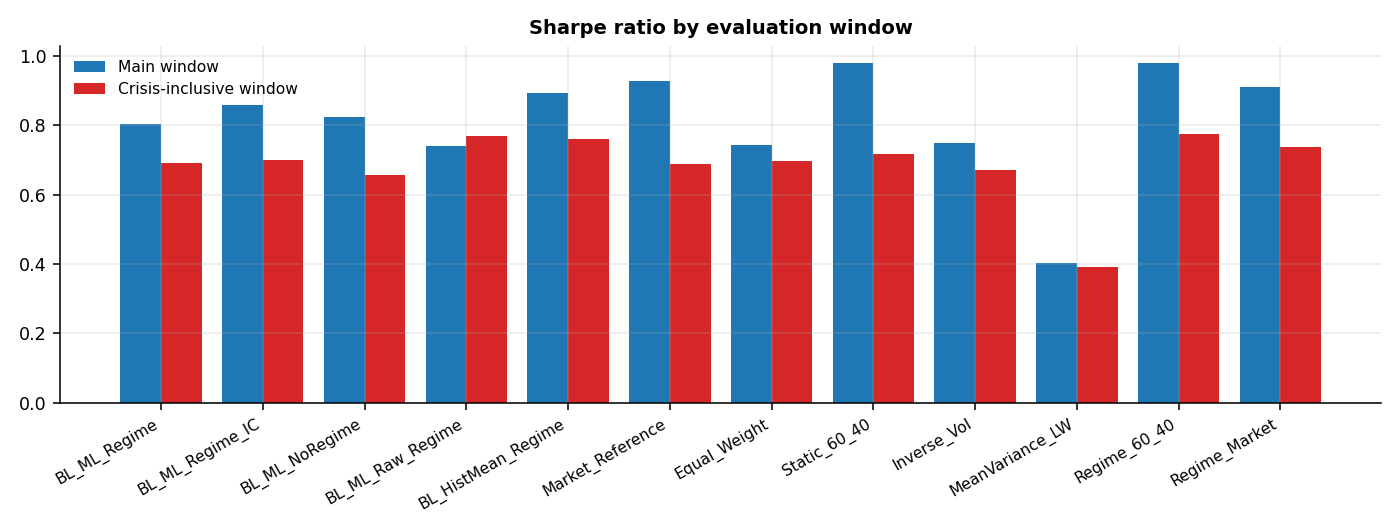

In [11]:
from IPython.display import Image

Image(str(P.figures / "16_window_robustness.png"))

In [12]:
pd.read_csv(P.tables / "prior_comparison.csv")

,Prior,Variant,Sharpe,Sharpe_PriorPortfolio,Diff,CI_low,CI_high,p_value,MaxDrawdown,MaxDrawdown_PriorPortfolio
0,reference,BL_ML_Regime,0.804431,0.926883,-0.122452,-0.309727,0.040234,0.172207,-0.161381,-0.210603
1,reference,BL_ML_Regime_IC,0.859080,0.926883,-0.067803,-0.197191,0.046144,0.289928,-0.131158,-0.210603
2,reference,BL_HistMean_Regime,0.893913,0.926883,-0.032970,-0.194031,0.110077,0.677831,-0.153128,-0.210603
3,equal,BL_ML_Regime,0.589062,0.743854,-0.154792,-0.321145,-0.010465,0.053737,-0.176837,-0.235862
4,equal,BL_ML_Regime_IC,0.648064,0.743854,-0.095790,-0.224922,0.024835,0.137716,-0.153067,-0.235862
5,equal,BL_HistMean_Regime,0.651268,0.743854,-0.092585,-0.248634,0.051611,0.240690,-0.169302,-0.235862
6,inverse_vol,BL_ML_Regime,0.601554,0.750727,-0.149173,-0.364602,0.027249,0.140715,-0.142744,-0.174322
7,inverse_vol,BL_ML_Regime_IC,0.690717,0.750727,-0.060010,-0.201157,0.069316,0.403649,-0.110466,-0.174322
8,inverse_vol,BL_HistMean_Regime,0.693016,0.750727,-0.057711,-0.250055,0.103419,0.532117,-0.134237,-0.174322


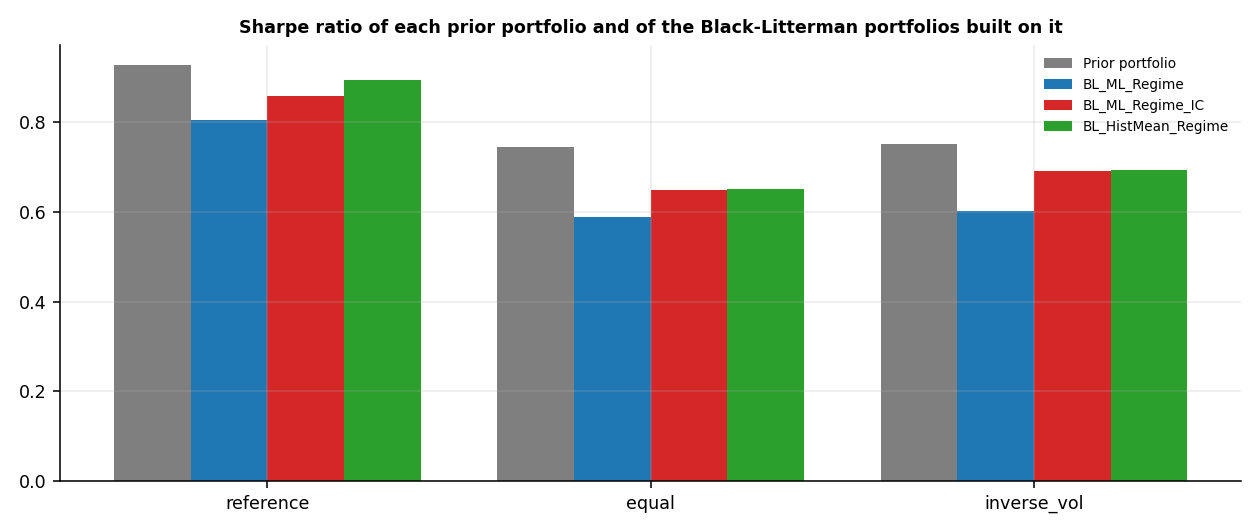

In [13]:
from IPython.display import Image

Image(str(P.figures / "17_prior_comparison.png"))

In [14]:
pd.read_csv(P.tables / "holdout_status.csv")

,freeze_date,spec_hash,spec_unchanged,months_since_freeze,inference_possible
0,2026-07-31,5dc8a748344f1fd0,True,0,False


In [15]:
pd.read_csv(P.tables / "sensitivity.csv")

,Parameter,Value,IsDefault,Variant,Sharpe,AnnVol,MaxDrawdown,AnnTurnover,AvgCash,Sharpe_60_40
0,tau,0.025,False,BL_ML_Regime,0.839723,0.073462,-0.148613,1.705519,0.156377,0.980462
1,tau,0.025,False,BL_ML_Regime_IC,0.859023,0.071324,-0.132637,1.261984,0.173620,0.980462
2,tau,0.05,True,BL_ML_Regime,0.804431,0.074971,-0.161381,2.119223,0.162324,0.980462
3,tau,0.05,True,BL_ML_Regime_IC,0.859080,0.070034,-0.131158,1.324003,0.183665,0.980462
4,tau,0.1,False,BL_ML_Regime,0.743192,0.078620,-0.176243,2.661180,0.165147,0.980462
5,tau,0.1,False,BL_ML_Regime_IC,0.860834,0.067884,-0.128411,1.441475,0.202413,0.980462
6,tau,0.2,False,BL_ML_Regime,0.653457,0.084393,-0.190396,3.217560,0.162332,0.980462
7,tau,0.2,False,BL_ML_Regime_IC,0.851918,0.064799,-0.123630,1.597845,0.233747,0.980462
8,base_delta,1.5,False,BL_ML_Regime,0.735691,0.083167,-0.180927,2.733077,0.130277,0.980462
9,base_delta,1.5,False,BL_ML_Regime_IC,0.855001,0.070676,-0.133449,1.445335,0.171873,0.980462


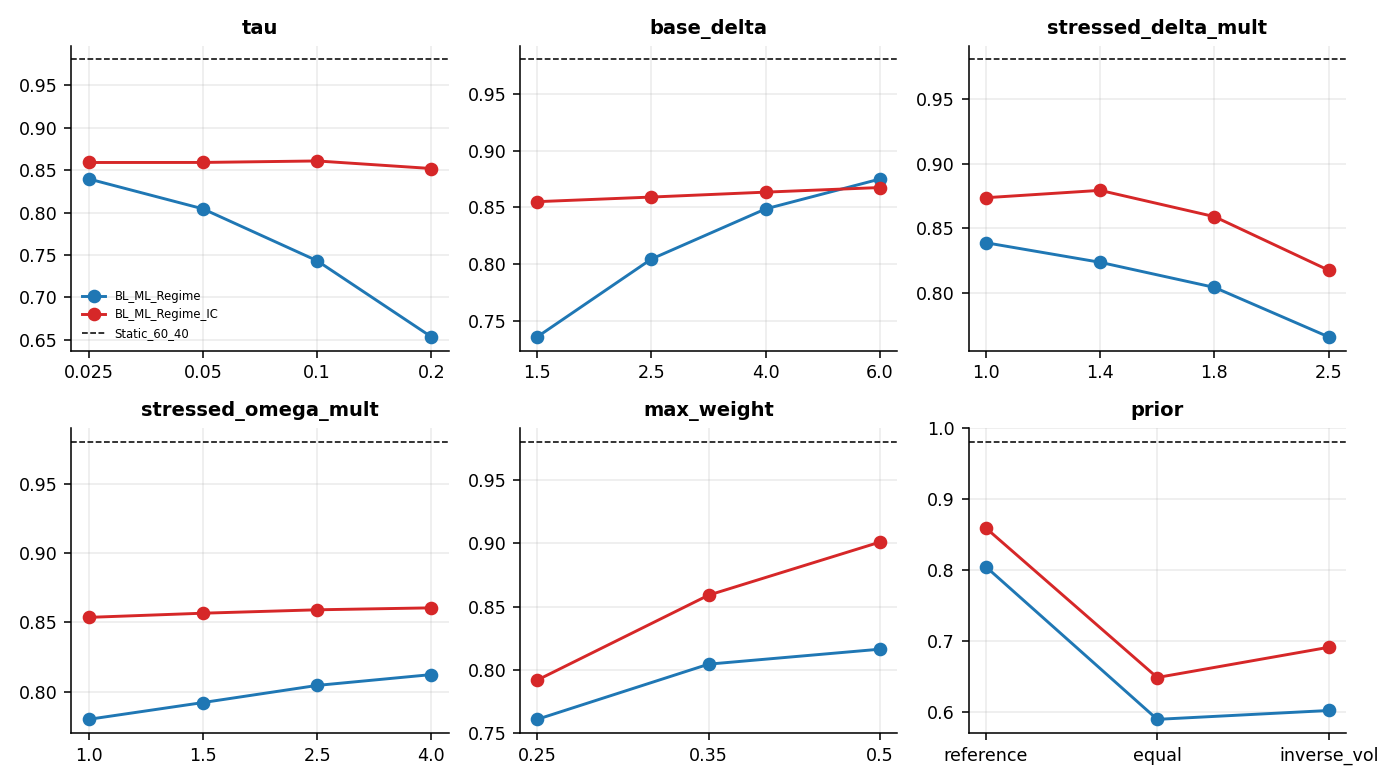

In [16]:
from IPython.display import Image

Image(str(P.figures / "13_sensitivity.png"))